# Evaluación Formativa 2 — Modelamiento predictivo

**Curso:** MCDI501 — Estadística Computacional para la Toma de Decisiones  
**Proyecto:** *Online Shoppers Purchasing Intention*  
**Integrantes:** Verónica Durán Cisterna · Raúl Moya Arriagada · Daniela Rojas Vilches · Manuel Sánchez Cárcamo  
**Docente:** Dr. Jean Paul Maidana González  

## Objetivo

Ensayar el flujo completo de modelamiento predictivo mediante **regresión logística**, integrando explícitamente los resultados obtenidos en las Evaluaciones Sumativas 1 y 2. Se prepara el conjunto de datos, se seleccionan predictores sustentados en evidencia previa, se ajusta e interpreta el modelo y se evalúa su desempeño sobre un conjunto de prueba.

La pregunta que guía el proyecto se mantiene en términos asociativos:

> **¿Qué características del comportamiento de navegación de los usuarios se relacionan con la probabilidad de que una sesión de comercio electrónico termine en una compra?**

El análisis no pretende establecer relaciones causales.

## 1. Librerías y reproducibilidad

Se fija `RANDOM_STATE = 42` para hacer reproducibles los faltantes MCAR y la partición entrenamiento/prueba. Se utilizan `pandas` y `numpy` para manipulación, `statsmodels` para inferencia y VIF, y `scikit-learn` para preprocesamiento y evaluación predictiva.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, roc_curve, roc_auc_score,
    mean_absolute_error, mean_squared_error
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
MISSING_RATE = 0.12
np.random.seed(RANDOM_STATE)

print("Entorno preparado. Semilla:", RANDOM_STATE)

Entorno preparado. Semilla: 42


## 2. Carga y verificación del dataset

El notebook busca el archivo mediante rutas relativas habituales del repositorio, de modo que pueda ejecutarse desde la raíz o desde una subcarpeta como `F2/`.

La unidad de análisis es una **sesión de navegación** y la variable objetivo es `Revenue` (`True` = la sesión termina en compra).

In [2]:
candidatos = [
    Path("data/raw/online_shoppers_intention.csv"),
    Path("../data/raw/online_shoppers_intention.csv"),
    Path("online_shoppers_intention.csv"),
]

ruta = next((p for p in candidatos if p.exists()), None)

if ruta is None:
    raise FileNotFoundError(
        "No se encontró online_shoppers_intention.csv. "
        "Ejecute el notebook desde la raíz del repositorio o desde F2/."
    )

df = pd.read_csv(ruta)

print("Archivo:", ruta.resolve())
print("Dimensiones:", df.shape)
display(df.head())

Archivo: /tmp/claude-0/-home-user-Estadistica-Computacional/9f49e535-2194-50d8-8323-b9676462fcf2/scratchpad/f2run/data/raw/online_shoppers_intention.csv
Dimensiones: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [3]:
print("Tipos de datos:")
display(df.dtypes.to_frame("dtype"))

print("\nValores faltantes totales:", int(df.isna().sum().sum()))
print("Filas con atributos exactamente coincidentes:", int(df.duplicated().sum()))

print("\nDistribución de Revenue:")
display(
    df["Revenue"]
    .value_counts(dropna=False)
    .rename("n")
    .to_frame()
    .assign(proporcion=lambda x: x["n"] / len(df))
)

Tipos de datos:


,dtype
Administrative,int64
Administrative_Duration,float64
Informational,int64
Informational_Duration,float64
ProductRelated,int64
ProductRelated_Duration,float64
BounceRates,float64
ExitRates,float64
PageValues,float64
SpecialDay,float64



Valores faltantes totales: 0
Filas con atributos exactamente coincidentes: 125

Distribución de Revenue:


,n,proporcion
Revenue,,
False,10422,0.845255
True,1908,0.154745


## 3. Evidencia previa S1 → S2 → F2

El punto de partida de esta evaluación formativa no es el dato crudo, sino la evidencia acumulada y validada en las dos entregas sumativas anteriores (sin repetir sus cálculos):

1. **Desbalance de la variable objetivo (`Revenue`) y pruebas de hipótesis (S1 y S2):** En S1 se determinó que la base contiene $12.330$ sesiones sin valores faltantes originales y que `Revenue` presenta un fuerte desbalance ($15,47\%$ de sesiones terminan en compra, IC clásico del $95\%: [0,1483; 0,1612]$). Para `PageValues`, la prueba de Mann-Whitney de S1 ($p < 0,001$; efecto grande, $r_{rb} = 0,727$) y la **prueba de permutación de S2** ($10.000$ permutaciones, $p \approx 0,0001$) confirmaron diferencias significativas entre sesiones con y sin compra; descriptivamente, S1 también mostró menor `ExitRates` y mayor `ProductRelated_Duration` en las sesiones con compra. Para variables categóricas, `VisitorType` mostró asociación estadísticamente significativa ($\chi^2 = 135,25$, $p < 0,001$; validada en S2 por permutación de $\chi^2$, $p \approx 0,0001$), aunque con una magnitud de efecto práctica pequeña ($V \text{ de Cramer} = 0,105$), mientras que `Weekend` exhibió diferencias descriptivas leves en la tasa de conversión.
2. **Estabilidad de correlaciones mediante Bootstrap (S2):** Con $10.000$ remuestras pareadas e intervalos de confianza del $95\%$ por método percentil (ninguno cruzando el cero), S2 confirmó como altamente estables cuatro relaciones lineales entre predictores numéricos: `BounceRates`–`ExitRates` ($r \approx 0,913$), `ProductRelated`–`ProductRelated_Duration` ($r \approx 0,861$), `Informational`–`Informational_Duration` ($r \approx 0,619$) y `Administrative`–`Administrative_Duration` ($r \approx 0,602$). Esta evidencia sustenta dos decisiones metodológicas clave: (a) descartar la inclusión simultánea de ambos miembros de cada par para evitar multicolinealidad (la retroalimentación docente de S2 advirtió que `BounceRates` y `ExitRates` superan $\text{VIF} = 6$ juntas; se verifica en la sección 5.2), y (b) utilizar estas fuertes relaciones bivariadas como base para el diseño de la imputación en S3.
3. **Parámetros robustos, asimetría y tratamiento de outliers (S2):** En S2, la validación Bootstrap de las medias ($10.000$ remuestras) mostró que los intervalos **BCa se desplazan sistemáticamente hacia arriba** respecto al método percentil, reflejando la fuerte asimetría positiva de las variables de navegación. Asimismo, el análisis de robustez reveló que en `PageValues` la **media recortada al $5\%$ disminuye un $55,05\%$** respecto a la media muestral (siendo su mediana exactamente $0$), lo que demuestra que el IC de la media es estable por el gran tamaño muestral, pero la media aritmética no describe la sesión típica. Finalmente, dado que el diagnóstico **Jackknife** no identificó una observación individual anómala o error de registro que dominara por sí sola los estimadores, **no se eliminan outliers**, sino que se aplican estadísticos robustos (imputación por mediana) y escalamiento estándar.

In [4]:
# Documentación explícita de los insumos validados en S1 y S2
resumen_insumos_s1_s2 = pd.DataFrame([
    {"Variable / Par": "PageValues", "Hallazgo_S1": "Mann-Whitney p<0,001, r_rb = 0,727; mediana = 0", "Validacion_S2": "Permutación (10.000), p ≈ 0,0001; IC estable; media recortada 5% -55,05%", "Uso_en_F2": "Predictor continuo (con análisis de sensibilidad por posible filtración)"},
    {"Variable / Par": "BounceRates vs ExitRates", "Hallazgo_S1": "r = 0,913 (p<0,001); asoc. negativa con compra", "Validacion_S2": "Correlación estable (10.000 remuestras); VIF > 6 juntas según retroalimentación S2", "Uso_en_F2": "Se retiene solo ExitRates + Variable para experimento MCAR (12%)"},
    {"Variable / Par": "ProductRelated vs Duration", "Hallazgo_S1": "r = 0,861 (p<0,001); asoc. positiva con compra", "Validacion_S2": "Correlación estable (10.000 remuestras); alta redundancia", "Uso_en_F2": "Se retiene solo ProductRelated_Duration + Experimento MCAR (12%)"},
    {"Variable / Par": "VisitorType", "Hallazgo_S1": "Chi2 p<0,001; V de Cramer = 0,105 (magnitud pequeña)", "Validacion_S2": "Permutación χ² (10.000), p ≈ 0,0001", "Uso_en_F2": "Predictor categórico (One-Hot Encoding, base = New_Visitor)"},
    {"Variable / Par": "Weekend", "Hallazgo_S1": "Diferencia descriptiva leve en conversión (17,4% vs 14,9%)", "Validacion_S2": "Efecto contextual secundario", "Uso_en_F2": "Predictor binario de control temporal (candidato a evaluar en S3)"}
])
display(resumen_insumos_s1_s2)

,Variable / Par,Hallazgo_S1,Validacion_S2,Uso_en_F2
0,PageValues,"Mann-Whitney p<0,001, r_rb = 0,727; mediana = 0","Permutación (10.000), p ≈ 0,0001; IC estable; ...",Predictor continuo (con análisis de sensibilid...
1,BounceRates vs ExitRates,"r = 0,913 (p<0,001); asoc. negativa con compra",Correlación estable (10.000 remuestras); VIF >...,Se retiene solo ExitRates + Variable para expe...
2,ProductRelated vs Duration,"r = 0,861 (p<0,001); asoc. positiva con compra",Correlación estable (10.000 remuestras); alta ...,Se retiene solo ProductRelated_Duration + Expe...
3,VisitorType,"Chi2 p<0,001; V de Cramer = 0,105 (magnitud pe...","Permutación χ² (10.000), p ≈ 0,0001","Predictor categórico (One-Hot Encoding, base =..."
4,Weekend,"Diferencia descriptiva leve en conversión (17,...",Efecto contextual secundario,Predictor binario de control temporal (candida...


## 4. Preparación de datos para modelamiento

### 4.1 Generación controlada de faltantes MCAR

Siguiendo la pauta oficial para bases sin valores ausentes de origen, se seleccionan dos variables numéricas continuas relevantes para el problema: `ProductRelated_Duration` y `ExitRates`. 

**Justificación de esta elección:** Según la matriz de correlaciones de S1 y la validación Bootstrap de S2, ambas variables poseen correlaciones lineales fuertes y estables con otros predictores del dataset (`ExitRates` con `BounceRates`, $r = 0,913$; `ProductRelated_Duration` con `ProductRelated`, $r = 0,861$, además de `Administrative_Duration` e `Informational_Duration`). Esto garantiza que en la **Sumativa 3** dispongamos de entre $3$ y $5$ predictores numéricos óptimos para ajustar los modelos de **imputación mediante regresión lineal múltiple**.

Se elimina exactamente el **$12\%$** de los valores de cada variable ($1.480$ registros por variable) bajo un mecanismo **Completamente Aleatorio (MCAR)** utilizando semillas reproducibles (`RANDOM_STATE + i` para cada variable). La copia completa se conserva como `df_original`. La variable objetivo `Revenue` no se modifica ni se utilizará como predictor de imputación. Antes de introducir los valores `NaN`, se resguarda una copia exacta de los valores verdaderos (`valores_originales_mcar`) para cuantificar el error real de imputación (MAE y RMSE).

In [5]:
VARIABLES_MCAR = ["ProductRelated_Duration", "ExitRates"]

df_original = df.copy()
valores_originales_mcar = df_original[VARIABLES_MCAR].copy()
indices_mcar = {}

for i, variable in enumerate(VARIABLES_MCAR):
    rng = np.random.default_rng(RANDOM_STATE + i)
    n_missing = round(MISSING_RATE * len(df))
    idx = rng.choice(df.index.to_numpy(), size=n_missing, replace=False)
    indices_mcar[variable] = idx
    df.loc[idx, variable] = np.nan

faltantes = df.isna().sum()
display(pd.DataFrame({
    "n_faltantes": faltantes[faltantes > 0],
    "porcentaje": 100 * faltantes[faltantes > 0] / len(df)
}).round(2))
print("Faltantes en Revenue:", int(df["Revenue"].isna().sum()))
print("Filas con al menos un faltante:", int(df[VARIABLES_MCAR].isna().any(axis=1).sum()),
      f"({df[VARIABLES_MCAR].isna().any(axis=1).mean():.1%})")

,n_faltantes,porcentaje
ProductRelated_Duration,1480,12.0
ExitRates,1480,12.0


Faltantes en Revenue: 0
Filas con al menos un faltante: 2772 (22.5%)


### 4.2 Selección de predictores

Se seleccionan cinco variables:

1. **`PageValues` (Numérica):** Presentó la asociación positiva más fuerte con `Revenue` en S1 y S2. Se incorpora en este modelo base para evaluar el flujo completo, pero atendiendo la retroalimentación de S2 sobre su posible carácter *target-proximal* (riesgo de filtración de información si se calcula al cierre de la sesión), su permanencia se revisa en S3: allí, por indicación docente, `PageValues` se excluye de los modelos principales y solo se evalúa como escenario condicionado a confirmar su disponibilidad.
2. **`ExitRates` (Numérica):** Indicador directo de abandono de navegación. Como S2 demostró que su correlación con `BounceRates` es de $0,913$ (juntas superan $\text{VIF} = 6$, según la retroalimentación de S2 y la verificación de la sección 5.2), se selecciona únicamente `ExitRates` por capturar la tasa de salida en cualquier página de la sesión y no solo en la primera.
3. **`ProductRelated_Duration` (Numérica):** Mide la intensidad temporal de exploración del catálogo de productos. Se prefiere sobre el conteo simple `ProductRelated` ($r = 0,861$ en S2) para evitar redundancia y capturar mejor la profundidad de navegación.
4. **`VisitorType` (Categórica):** Validada en S1/S2 con asociación estadísticamente significativa ($\chi^2$, $p < 0,001$; permutación S2, $p \approx 0,0001$), aunque de magnitud pequeña ($V = 0,105$). Permite distinguir el perfil del visitante recurrente (`Returning_Visitor`) y otros (`Other`) frente al visitante nuevo (`New_Visitor`).
5. **`Weekend` (Binaria):** Incorporada como variable de control temporal a partir de las diferencias descriptivas observadas en S1 entre sesiones de fin de semana y días hábiles (su permanencia definitiva será contrastada mediante selección *stepwise* AIC/BIC en S3).

Esta selección combina evidencia estadística previa, interpretabilidad y control básico de redundancia.

In [6]:
predictores = [
    "PageValues",
    "ExitRates",
    "ProductRelated_Duration",
    "VisitorType",
    "Weekend",
]
target = "Revenue"

modelo_df = df[predictores + [target]].copy()

# Revenue a 0/1
modelo_df[target] = modelo_df[target].astype(int)

print("Variables seleccionadas:", predictores)
display(modelo_df.head())

Variables seleccionadas: ['PageValues', 'ExitRates', 'ProductRelated_Duration', 'VisitorType', 'Weekend']


,PageValues,ExitRates,ProductRelated_Duration,VisitorType,Weekend,Revenue
0,0.0,0.20,0.000000,Returning_Visitor,False,0
1,0.0,0.10,64.000000,Returning_Visitor,False,0
2,0.0,0.20,0.000000,Returning_Visitor,False,0
3,0.0,0.14,2.666667,Returning_Visitor,False,0
4,0.0,0.05,627.500000,Returning_Visitor,True,0


### 4.3 Partición entrenamiento/prueba 70/30

La partición se realiza **después de generar la máscara MCAR y antes de estimar parámetros de preprocesamiento**, con `random_state=42` y `stratify=y`. La estratificación es importante debido al desbalance de `Revenue`, ya que mantiene aproximadamente la misma proporción de compra en entrenamiento y prueba.

In [7]:
X = modelo_df[predictores].copy()
y = modelo_df[target].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print(f"Compra train: {y_train.mean():.4%}")
print(f"Compra test : {y_test.mean():.4%}")

Train: (8631, 5) | Test: (3699, 5)
Compra train: 15.4791%
Compra test : 15.4636%


### 4.4 Imputación, codificación y estandarización

En esta Formativa 2 se aplica una estrategia básica de tratamiento de faltantes: **imputación simple mediante la mediana**.

**Justificación metodológica:**
- **¿Por qué mediana y no eliminación de casos?** Al haberse inducido un $12\%$ de faltantes MCAR de forma independiente en dos columnas, eliminar las filas incompletas descartaría aproximadamente el $22,6\%$ de la base de datos ($1 - 0,88 \times 0,88$), reduciendo drásticamente el número de compras disponibles para entrenar.
- **¿Por qué mediana y no media aritmética?** Los análisis de S1 y S2 demostraron que `ProductRelated_Duration` y `ExitRates` presentan distribuciones fuertemente asimétricas a la derecha y colas pesadas. La mediana es un estadístico de orden robusto que no se ve arrastrado por las sesiones de duración extrema, preservando mejor la ubicación central de la distribución.
- **Prevención de fuga de información (*Data Leakage*) y estandarización:** Tanto las medianas de imputación como las medias y desviaciones estándar del escalador (`StandardScaler`) se calculan **exclusivamente sobre el subconjunto de entrenamiento ($70\%$)** y luego se aplican al subconjunto de prueba ($30\%$). Las variables numéricas se estandarizan (media $0$, desviación estándar $1$) para que sus coeficientes y *Odds Ratios* sean comparables en términos de una desviación estándar. `VisitorType` se codifica mediante *one-hot encoding*, usando una categoría de referencia (`New_Visitor`), y `Weekend` se transforma a binaria 0/1.

In [8]:
numeric_features = ["PageValues", "ExitRates", "ProductRelated_Duration"]
categorical_features = ["VisitorType"]

# Conversión explícita de Weekend a entero
X_train = X_train.copy()
X_test = X_test.copy()
X_train["Weekend"] = X_train["Weekend"].astype(int)
X_test["Weekend"] = X_test["Weekend"].astype(int)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_features),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), categorical_features),
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)

X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

X_train_model = pd.DataFrame(X_train_proc, columns=feature_names, index=X_train.index)
X_test_model = pd.DataFrame(X_test_proc, columns=feature_names, index=X_test.index)

imputer = preprocessor.named_transformers_["num"].named_steps["imputer"]
display(pd.DataFrame({"Variable": numeric_features,
                      "Mediana_train": imputer.statistics_}).round(4))
print("NaN tras preprocesamiento (train/test):",
      int(X_train_model.isna().sum().sum()), int(X_test_model.isna().sum().sum()))

display(X_train_model.head())
print("Variables finales del modelo:", list(X_train_model.columns))

,Variable,Mediana_train
0,PageValues,0.0000
1,ExitRates,0.0250
2,ProductRelated_Duration,592.8375


NaN tras preprocesamiento (train/test): 0 0


,PageValues,ExitRates,ProductRelated_Duration,VisitorType_Other,VisitorType_Returning_Visitor,Weekend
7460,-0.320111,-0.657779,-0.422625,0.0,0.0,0.0
4687,-0.320111,-0.657779,-0.333367,0.0,1.0,0.0
790,-0.320111,-0.224083,-0.474631,0.0,1.0,0.0
9057,-0.320111,-0.529155,-0.006114,0.0,1.0,0.0
225,-0.320111,1.259158,-0.598109,0.0,1.0,1.0


Variables finales del modelo: ['PageValues', 'ExitRates', 'ProductRelated_Duration', 'VisitorType_Other', 'VisitorType_Returning_Visitor', 'Weekend']


### 4.5 Error de la imputación por mediana

Como los faltantes son artificiales, se conocen los valores verdaderos. Se calcula el **MAE** y el **RMSE** de la imputación por mediana (mediana aprendida solo en entrenamiento), como línea base para compararla en S3 con la imputación por regresión.

In [9]:
errores = []
for variable in VARIABLES_MCAR:
    mediana_train = X_train[variable].median()
    idx = df.index[df[variable].isna()]
    real = valores_originales_mcar.loc[idx, variable]
    errores.append({
        "Variable": variable,
        "n_ocultos": len(idx),
        "Mediana_train": mediana_train,
        "MAE_mediana": mean_absolute_error(real, np.full(len(idx), mediana_train)),
        "RMSE_mediana": np.sqrt(mean_squared_error(real, np.full(len(idx), mediana_train)))
    })
tabla_error_mediana = pd.DataFrame(errores)
display(tabla_error_mediana.round(4))

,Variable,n_ocultos,Mediana_train,MAE_mediana,RMSE_mediana
0,ProductRelated_Duration,1480,592.8375,982.1473,1862.2494
1,ExitRates,1480,0.0250,0.0271,0.0472


## 5. Modelo de regresión logística

Para cumplir el componente inferencial se ajusta primero una regresión logística con `statsmodels`. Esto permite obtener coeficientes, errores estándar, pruebas de significancia e intervalos de confianza. Posteriormente se interpretan los **odds ratios** (`exp(β)`).

Para las variables numéricas estandarizadas, el OR representa el cambio multiplicativo en los *odds* de compra asociado a un aumento de **1 desviación estándar**, manteniendo constantes los demás predictores.

In [10]:
X_sm = sm.add_constant(X_train_model, has_constant="add")

logit_sm = sm.Logit(y_train, X_sm)
resultado_sm = logit_sm.fit(disp=False, maxiter=1000)

print(resultado_sm.summary())

                           Logit Regression Results                           
Dep. Variable:                Revenue   No. Observations:                 8631
Model:                          Logit   Df Residuals:                     8624
Method:                           MLE   Df Model:                            6
Date:                Mon, 26 Oct 2026   Pseudo R-squ.:                  0.3096
Time:                        01:51:00   Log-Likelihood:                -2567.7
converged:                       True   LL-Null:                       -3719.4
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const                            -2.0469      0.109    -18.767      0.000      -2.261      -1.833
PageValues                        1.5216      0.052     29.274      0.000 

In [11]:
coef = resultado_sm.params
conf = resultado_sm.conf_int()

tabla_coef = pd.DataFrame({
    "Coeficiente": coef,
    "Odds_ratio": np.exp(coef),
    "p_valor": resultado_sm.pvalues,
    "OR_IC95_inf": np.exp(conf[0]),
    "OR_IC95_sup": np.exp(conf[1]),
})

tabla_coef["Significativo_5%"] = np.where(
    tabla_coef["p_valor"] < 0.05, "Sí", "No"
)

display(tabla_coef.round(4))

,Coeficiente,Odds_ratio,p_valor,OR_IC95_inf,OR_IC95_sup,Significativo_5%
const,-2.0469,0.1291,0.0000,0.1043,0.1599,Sí
PageValues,1.5216,4.5794,0.0000,4.1358,5.0704,Sí
ExitRates,-1.0065,0.3655,0.0000,0.2973,0.4493,Sí
ProductRelated_Duration,0.2511,1.2854,0.0000,1.2072,1.3687,Sí
VisitorType_Other,-0.7172,0.4881,0.2386,0.1481,1.6089,No
VisitorType_Returning_Visitor,-0.2540,0.7757,0.0123,0.6358,0.9464,Sí
Weekend,0.1745,1.1907,0.0378,1.0099,1.4038,Sí


### 5.1 Interpretación automática de coeficientes y odds ratios

La tabla siguiente genera una lectura consistente de cada predictor. La interpretación final debe considerar simultáneamente signo, OR, intervalo de confianza, p-valor y contexto.

In [12]:
for variable in tabla_coef.index:
    if variable == "const":
        continue

    beta = tabla_coef.loc[variable, "Coeficiente"]
    or_ = tabla_coef.loc[variable, "Odds_ratio"]
    p = tabla_coef.loc[variable, "p_valor"]
    sentido = "aumentan" if beta > 0 else "disminuyen"
    sig = "estadísticamente significativo" if p < 0.05 else "no estadísticamente significativo"

    print(
        f"{variable}: β={beta:.4f}, OR={or_:.4f}, p={p:.4g}. "
        f"Manteniendo constantes los demás predictores, los odds de compra {sentido}; "
        f"el predictor es {sig} al 5%."
    )

PageValues: β=1.5216, OR=4.5794, p=2.199e-188. Manteniendo constantes los demás predictores, los odds de compra aumentan; el predictor es estadísticamente significativo al 5%.
ExitRates: β=-1.0065, OR=0.3655, p=1.241e-21. Manteniendo constantes los demás predictores, los odds de compra disminuyen; el predictor es estadísticamente significativo al 5%.
ProductRelated_Duration: β=0.2511, OR=1.2854, p=4.406e-15. Manteniendo constantes los demás predictores, los odds de compra aumentan; el predictor es estadísticamente significativo al 5%.
VisitorType_Other: β=-0.7172, OR=0.4881, p=0.2386. Manteniendo constantes los demás predictores, los odds de compra disminuyen; el predictor es no estadísticamente significativo al 5%.
VisitorType_Returning_Visitor: β=-0.2540, OR=0.7757, p=0.01232. Manteniendo constantes los demás predictores, los odds de compra disminuyen; el predictor es estadísticamente significativo al 5%.
Weekend: β=0.1745, OR=1.1907, p=0.03779. Manteniendo constantes los demás predi

### 5.2 Diagnóstico de multicolinealidad mediante VIF

El VIF se calcula sobre las variables predictoras ya codificadas. Como referencia práctica:

- VIF cercano a 1: baja colinealidad.
- VIF > 5: requiere atención.
- VIF > 10: problema severo.

La selección previa ya evita incluir simultáneamente los dos pares de correlaciones altas validadas en S2.

Tal como se indicó en la retroalimentación de la Sumativa 2, antes de dar por válido el modelo es indispensable verificar qué ocurre con el VIF cuando coexisten los pares colineales detectados en S1/S2 (`BounceRates` con `ExitRates` y `ProductRelated` con `ProductRelated_Duration`) versus el modelo depurado que seleccionamos:

In [13]:
# 1. Verificación previa: VIF sobre los datos originales de entrenamiento con pares redundantes
vars_previas = ["PageValues", "ExitRates", "BounceRates", "ProductRelated_Duration", "ProductRelated"]

# Se usa la base completa (antes de MCAR) para que el diagnóstico no dependa de la imputación
df_ref = df_original.loc[X_train.index, vars_previas].copy()
X_orig_train = sm.add_constant(
    StandardScaler().fit_transform(df_ref),
    has_constant="add"
)
nombres_previos = ["const"] + vars_previas
vif_previo = pd.DataFrame({
    "Variable (Con pares redundantes)": nombres_previos,
    "VIF_Sin_Filtrar": [variance_inflation_factor(X_orig_train, i) for i in range(X_orig_train.shape[1])]
}).query("`Variable (Con pares redundantes)` != 'const'").sort_values("VIF_Sin_Filtrar", ascending=False)

print("1. Diagnóstico previo (incluyendo pares colineales BounceRates y ProductRelated):")
display(vif_previo.round(3))

# 2. VIF del modelo final ajustado en F2 (asegurando DataFrame y constante local de manera segura)
if not isinstance(X_train_proc, pd.DataFrame):
    try:
        feat_names = preprocessor.get_feature_names_out()
    except Exception:
        feat_names = [f"var_{i}" for i in range(X_train_proc.shape[1])]
    X_train_proc_df = pd.DataFrame(X_train_proc, columns=feat_names, index=X_train.index)
else:
    X_train_proc_df = X_train_proc.copy()

# Crear la matriz con constante de forma local y segura para evitar NameError
X_train_proc_sm = sm.add_constant(X_train_proc_df, has_constant="add")

tabla_vif = pd.DataFrame({
    "Variable": X_train_proc_df.columns,
    "VIF": [
        variance_inflation_factor(X_train_proc_df.astype(float).values, i)
        for i in range(X_train_proc_df.shape[1])
    ],
    "VIF (con constante)": [
        variance_inflation_factor(X_train_proc_sm.astype(float).values, i + 1)
        for i in range(X_train_proc_df.shape[1])
    ]
}).sort_values("VIF", ascending=False)

print("\n2. Diagnóstico VIF del modelo seleccionado en F2 (descartando BounceRates y ProductRelated):")
display(tabla_vif.round(3))

1. Diagnóstico previo (incluyendo pares colineales BounceRates y ProductRelated):


,Variable (Con pares redundantes),VIF_Sin_Filtrar
2,ExitRates,6.535
3,BounceRates,6.122
5,ProductRelated,3.766
4,ProductRelated_Duration,3.611
1,PageValues,1.044



2. Diagnóstico VIF del modelo seleccionado en F2 (descartando BounceRates y ProductRelated):


,Variable,VIF,VIF (con constante)
1,ExitRates,1.119,1.119
4,VisitorType_Returning_Visitor,1.117,1.117
2,ProductRelated_Duration,1.076,1.076
3,VisitorType_Other,1.056,1.056
0,PageValues,1.039,1.039
5,Weekend,1.005,1.005


**Conclusión del diagnóstico VIF:**
La primera tabla corrobora la advertencia analítica de S2: al incorporar simultáneamente `ExitRates` junto a `BounceRates` y `ProductRelated_Duration` junto a `ProductRelated`, `ExitRates` ($6,54$) y `BounceRates` ($6,12$) superan el umbral de alerta ($\text{VIF} > 6$), mientras que `ProductRelated` y `ProductRelated_Duration` quedan en torno a $3,6$–$3,8$. Al retener solamente un representante por cada dimensión conceptual, la segunda tabla evidencia que **los valores de VIF descienden al rango de $1,005$ a $1,119$**, situándose por debajo de los límites de riesgo. Si bien esto mitiga la multicolinealidad y previene la inflación de los errores estándar, conviene mantener presente que en conjuntos de datos observacionales la independencia lineal absoluta entre predictores no existe, por lo que la estabilidad de las estimaciones debe seguirse validando mediante remuestreo (bootstrap) en las siguientes fases del proyecto.

## 6. Evaluación de desempeño predictivo

Para evaluar generalización, el desempeño se calcula **exclusivamente sobre el conjunto de prueba**. Se utiliza el umbral convencional de 0,50 para la clasificación principal.

Debido al desbalance de `Revenue`, **accuracy no debe interpretarse aisladamente**. Son especialmente relevantes:

- **Precision**: de las sesiones predichas como compra, qué proporción realmente compra.
- **Recall (sensibilidad)**: de las sesiones que realmente compran, qué proporción identifica el modelo.
- **F1-score**: equilibrio entre precision y recall.
- **ROC-AUC**: capacidad de discriminación a través de todos los umbrales.

In [14]:
# Las probabilidades provienen del modelo inferencial ajustado con statsmodels
X_test_sm = sm.add_constant(X_test_model, has_constant="add")
prob_test = resultado_sm.predict(X_test_sm)
pred_test = (prob_test >= 0.50).astype(int)

metricas = pd.DataFrame({
    "Métrica": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Valor": [
        accuracy_score(y_test, pred_test),
        precision_score(y_test, pred_test, zero_division=0),
        recall_score(y_test, pred_test, zero_division=0),
        f1_score(y_test, pred_test, zero_division=0),
        roc_auc_score(y_test, prob_test),
    ]
})

display(metricas.round(4))

print("\nReporte de clasificación:")
print(classification_report(y_test, pred_test, target_names=["No compra", "Compra"], digits=4))

,Métrica,Valor
0,Accuracy,0.8805
1,Precision,0.7444
2,Recall,0.3462
3,F1-score,0.4726
4,ROC-AUC,0.8621



Reporte de clasificación:


              precision    recall  f1-score   support

   No compra     0.8911    0.9783    0.9326      3127
      Compra     0.7444    0.3462    0.4726       572

    accuracy                         0.8805      3699
   macro avg     0.8177    0.6622    0.7026      3699
weighted avg     0.8684    0.8805    0.8615      3699



### 6.1 Matriz de confusión

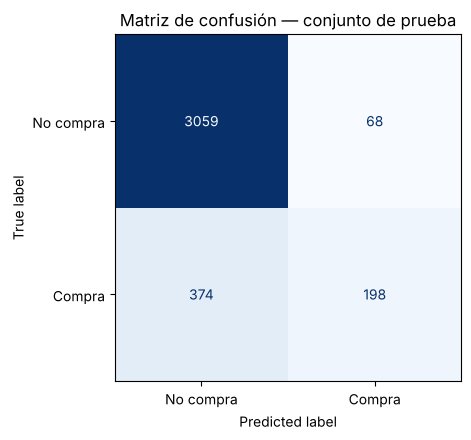

TN=3059, FP=68, FN=374, TP=198


In [15]:
cm = confusion_matrix(y_test, pred_test)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No compra", "Compra"]
).plot(ax=ax, cmap="Blues", colorbar=False)

ax.set_title("Matriz de confusión — conjunto de prueba")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

**Interpretación contextual:** en este problema los **falsos negativos (FN)** representan sesiones que sí terminaron en compra pero que el modelo clasificó como “no compra”. Por ello, un recall bajo de la clase positiva indicaría que el modelo pierde una fracción importante de compradores reales, aunque su accuracy global pudiera parecer elevada.

### 6.2 Curva ROC y AUC

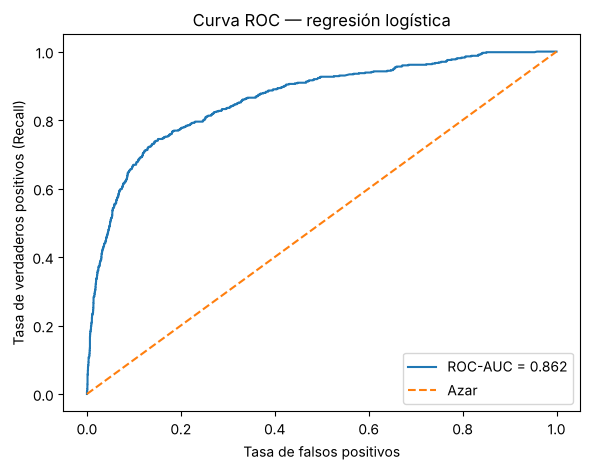

AUC = 0.8621: buena capacidad discriminativa.


In [16]:
fpr, tpr, thresholds = roc_curve(y_test, prob_test)
auc = roc_auc_score(y_test, prob_test)

fig, ax = plt.subplots(figsize=(6, 4.8))
ax.plot(fpr, tpr, label=f"ROC-AUC = {auc:.3f}")
ax.plot([0, 1], [0, 1], linestyle="--", label="Azar")
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos (Recall)")
ax.set_title("Curva ROC — regresión logística")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

if auc < 0.60:
    lectura_auc = "capacidad discriminativa baja"
elif auc < 0.70:
    lectura_auc = "capacidad discriminativa limitada"
elif auc < 0.80:
    lectura_auc = "capacidad discriminativa aceptable"
elif auc < 0.90:
    lectura_auc = "buena capacidad discriminativa"
else:
    lectura_auc = "capacidad discriminativa muy alta"

print(f"AUC = {auc:.4f}: {lectura_auc}.")

### 6.3 Comparación con una referencia simple

Dado el desbalance de clases, se calcula el accuracy que obtendría una regla ingenua que predijera siempre la clase mayoritaria (“no compra”). Esta comparación evita atribuir mérito predictivo a un accuracy alto que pueda explicarse solo por la distribución de clases.

In [17]:
accuracy_baseline = max(y_test.mean(), 1 - y_test.mean())
accuracy_modelo = accuracy_score(y_test, pred_test)

print(f"Accuracy baseline clase mayoritaria: {accuracy_baseline:.4f}")
print(f"Accuracy modelo logístico          : {accuracy_modelo:.4f}")
print(f"Mejora absoluta                    : {accuracy_modelo - accuracy_baseline:.4f}")

Accuracy baseline clase mayoritaria: 0.8454
Accuracy modelo logístico          : 0.8805
Mejora absoluta                    : 0.0351


## 7. Análisis crítico del modelo

La evaluación debe considerar dos dimensiones distintas:

1. **Inferencial:** los coeficientes, odds ratios, p-valores y VIF permiten estudiar la relación de los predictores con los odds de compra y diagnosticar multicolinealidad.
2. **Predictiva:** la matriz de confusión, precision, recall, F1 y ROC-AUC permiten evaluar cuánto generaliza el modelo a sesiones no utilizadas durante el ajuste.

Un predictor puede ser estadísticamente significativo sin que el modelo completo tenga desempeño suficiente para una aplicación práctica. Del mismo modo, un accuracy alto no garantiza una buena identificación de la clase minoritaria.

### Precaución especial: `PageValues`

`PageValues` se incluye porque S1 y S2 entregaron evidencia consistente de una asociación fuerte con `Revenue`. Sin embargo, es una variable conceptualmente próxima a la transacción. La retroalimentación docente de S2 indicó **dejar `PageValues` fuera hasta confirmar cuándo está disponible**. En S3 se aplica esa indicación: los modelos principales se ajustan sin `PageValues` y la variable solo se evalúa como escenario condicionado, para cuantificar cuánto del poder predictivo depende de información que podría no estar disponible en el momento real en que se quisiera anticipar la compra.

## 8. Síntesis y reflexión final

Los resultados obtenidos en S1 y S2 se integraron directamente en la construcción del modelo de regresión logística. S1 permitió identificar el desbalance de `Revenue`, la fuerte asociación de `PageValues` con la compra, la relación de `VisitorType` con la variable objetivo y pares de variables altamente correlacionadas. S2 confirmó mediante remuestreo la estabilidad de varios de estos resultados. En particular, las correlaciones elevadas y estables entre `BounceRates`–`ExitRates` y `ProductRelated`–`ProductRelated_Duration` justificaron no incorporar simultáneamente ambos miembros de cada par. Esta decisión resultó consistente con el diagnóstico posterior de multicolinealidad, ya que todos los predictores del modelo presentaron VIF inferiores a 1,2, mientras que al incluir los pares redundantes `ExitRates` y `BounceRates` superaban 6.

El modelo incorporó `PageValues`, `ExitRates`, `ProductRelated_Duration`, `VisitorType` y `Weekend`. `PageValues` presentó el efecto de mayor magnitud: su odds ratio fue aproximadamente 4,58, indicando que un aumento de una desviación estándar se asocia con una multiplicación de los odds de compra por aproximadamente 4,5, manteniendo constantes los demás predictores. `ExitRates` presentó una relación negativa (OR ≈ 0,37), mientras que `ProductRelated_Duration` mostró una asociación positiva (OR ≈ 1,29). La categoría `Returning_Visitor` y `Weekend` también resultaron estadísticamente significativas al 5 %, mientras que `VisitorType_Other` no presentó evidencia suficiente de asociación una vez controlados los demás predictores.

En el conjunto de prueba, el modelo alcanzó un accuracy de 88,05 %, precision de 74,44 %, recall de 34,62 %, F1-score de 47,26 % y ROC-AUC de 0,8621. El AUC indica una buena capacidad global de discriminación; sin embargo, el desempeño no debe evaluarse únicamente mediante accuracy debido al desbalance de la variable objetivo. La matriz de confusión mostró 3.059 verdaderos negativos, 68 falsos positivos, 374 falsos negativos y 198 verdaderos positivos. Por lo tanto, con el umbral convencional de 0,50 el modelo identifica correctamente solo el 34,62 % de las sesiones que realmente terminan en compra. Además, el accuracy de una clasificación ingenua basada exclusivamente en la clase mayoritaria sería aproximadamente 84,54 %, por lo que la mejora del modelo en esta métrica es de alrededor de 3,51 puntos porcentuales.

Los valores extremos no fueron eliminados automáticamente. Esta decisión es coherente con S2, donde las distribuciones mostraron sensibilidad a las colas, especialmente `PageValues`, pero el análisis jackknife no evidenció que una única observación dominara las estimaciones. Como la base original no tiene valores faltantes, se generó de forma reproducible un 12 % de faltantes MCAR en `ProductRelated_Duration` y `ExitRates` (22,5 % de las filas con al menos un faltante) y se imputaron con la mediana aprendida solo en entrenamiento. Al conocerse los valores verdaderos, se midió su error: RMSE de 1.862 s en `ProductRelated_Duration` y de 0,047 en `ExitRates`, línea base para compararla en S3 con la imputación por regresión. La partición 70/30 se realizó de forma estratificada y tanto la imputación como la estandarización se estimaron únicamente con los datos de entrenamiento para evitar fuga de información desde el conjunto de prueba.

De cara a la Sumativa 3, el principal desafío será mejorar la detección de la clase compra sin deteriorar excesivamente la precision. Siguiendo la retroalimentación de S2, se propone: (i) comparar eliminación, mediana e imputación por regresión; (ii) calcular el VIF antes de modelar y conservar solo `ExitRates` del par con `BounceRates`; (iii) dejar `PageValues` fuera de los modelos principales hasta confirmar su disponibilidad, dado que su proximidad a la transacción podría constituir *target leakage*; (iv) ponderar las clases (peso ≈ 3,2 para compras) y comparar tres modelos con validación cruzada; y (v) evaluar con bootstrap qué coeficientes conservan su signo. Estas mejoras permitirán determinar si el desempeño observado se mantiene bajo especificaciones alternativas y seleccionar un modelo final considerando no solo su capacidad discriminativa, sino también su utilidad para identificar correctamente sesiones con intención de compra.

## 9. Checklist de la rúbrica

| Criterio | Evidencia en el notebook |
|---|---|
| Preparación de datos (21 pts) | S1/S2 explícitos, faltantes, outliers, selección, train/test 70/30 estratificado y estandarización |
| Regresión logística (30 pts) | 5 predictores justificados, resumen, coeficientes, OR, significancia y VIF |
| Desempeño predictivo (30 pts) | Matriz de confusión, accuracy, precision, recall, F1, ROC y AUC con interpretación |
| Síntesis y reflexión (15 pts) | Integración S1/S2, evaluación crítica y mejoras concretas para S3 |

**Total de criterios cubiertos por diseño: 96 puntos posibles.** La calificación final depende de la ejecución correcta del notebook, los resultados obtenidos y la evaluación docente.